In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import joblib

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

np.random.seed(42)

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

from google.colab import files
import pandas as pd

# Open file upload window
uploaded = files.upload()

# Read the uploaded CSV file
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

print("Dataset uploaded successfully!")
print("Filename:", filename)
print("Dataset shape:", df.shape)

display(df.head())


Saving data.csv to data.csv
Dataset uploaded successfully!
Filename: data.csv
Dataset shape: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [3]:

print("Column names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDataset information:")
df.info()


Column names:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']

Missing values:
569

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null

Missing values: 569

Class counts:
diagnosis
B    357
M    212
Name: count, dtype: int64


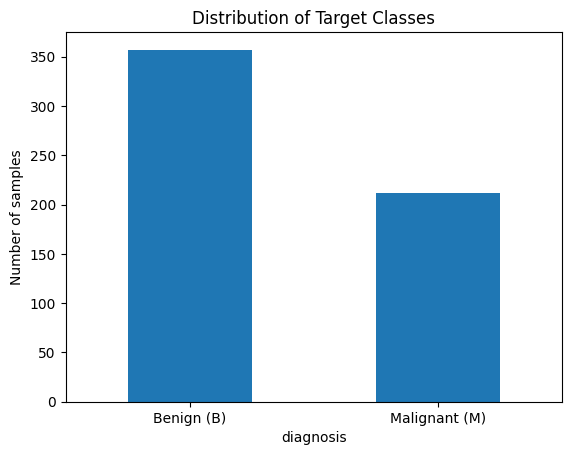

In [4]:

print("Missing values:", df.isnull().sum().sum())

print("\nClass counts:")
print(df["diagnosis"].value_counts())

df["diagnosis"].value_counts().plot(kind="bar", rot=0)
plt.xticks([0, 1], ["Benign (B)", "Malignant (M)"])
plt.ylabel("Number of samples")
plt.title("Distribution of Target Classes")
plt.show()


In [5]:

# Remove unnecessary columns
df = df.drop(
    columns=["id", "Unnamed: 32"],
    errors="ignore"
)

# Convert diagnosis into numeric labels
df["diagnosis"] = df["diagnosis"].map({
    "B": 0,
    "M": 1
})

# Remove rows with missing values
df = df.dropna()

print("Dataset prepared successfully!")
print(df.head())
print("\nTarget distribution:")
print(df["diagnosis"].value_counts())


Dataset prepared successfully!
   diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0          1        17.99         10.38          122.80     1001.0   
1          1        20.57         17.77          132.90     1326.0   
2          1        19.69         21.25          130.00     1203.0   
3          1        11.42         20.38           77.58      386.1   
4          1        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   symmetry_mean  ...  radius_worst  texture_worst  perimeter_worst  \
0         0.24

In [6]:

import numpy as np

X = df.drop(columns=["diagnosis"]).to_numpy(dtype=float)
y = df["diagnosis"].to_numpy(dtype=int).reshape(-1, 1)

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (569, 30)
Target shape: (569, 1)


In [7]:

from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Testing set:", X_test.shape, y_test.shape)


Training set: (398, 30) (398, 1)
Validation set: (85, 30) (85, 1)
Testing set: (86, 30) (86, 1)


In [8]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Feature scaling completed!")
print("First five scaled features:")
print(X_train[0, :5])


Feature scaling completed!
First five scaled features:
[1.70581999 1.04974466 2.12129465 1.66933676 2.27645789]


In [9]:

import numpy as np
import matplotlib.pyplot as plt

# Step activation: basic perceptron
def step_activation(z):
    return (z >= 0).astype(int)

# Sigmoid: output between 0 and 1
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

# ReLU: commonly used in hidden layers
def relu(z):
    return np.maximum(0, z)

# Tanh: output between -1 and 1
def tanh(z):
    return np.tanh(z)

print("Activation functions defined successfully!")


Activation functions defined successfully!


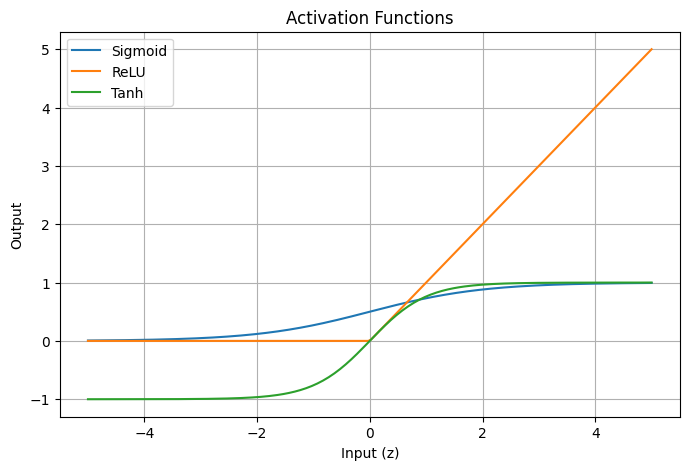

In [10]:

z = np.linspace(-5, 5, 200)

plt.figure(figsize=(8, 5))
plt.plot(z, sigmoid(z), label="Sigmoid")
plt.plot(z, relu(z), label="ReLU")
plt.plot(z, tanh(z), label="Tanh")

plt.xlabel("Input (z)")
plt.ylabel("Output")
plt.title("Activation Functions")
plt.legend()
plt.grid(True)
plt.show()


In [11]:

# Two input values
inputs = np.array([[1.0, 2.0]])

# Weights and bias
weights = np.array([[0.5], [-0.3]])
bias = -0.1

# Weighted sum
z = inputs @ weights + bias

# Apply step activation
prediction = step_activation(z)

print("Weighted sum:", z)
print("Perceptron output:", prediction)


Weighted sum: [[-0.2]]
Perceptron output: [[0]]


In [12]:

def forward_pass(X, params):
    W1 = params["W1"]
    b1 = params["b1"]
    W2 = params["W2"]
    b2 = params["b2"]

    # Input to hidden layer
    Z1 = X @ W1 + b1
    A1 = relu(Z1)

    # Hidden layer to output
    Z2 = A1 @ W2 + b2
    A2 = sigmoid(Z2)

    # Save values for backpropagation
    cache = (X, Z1, A1, Z2, A2)

    return A2, cache


print("Forward propagation implemented!")


Forward propagation implemented!


In [13]:

def binary_cross_entropy(y_true, y_pred):
    epsilon = 1e-12

    y_pred = np.clip(
        y_pred,
        epsilon,
        1 - epsilon
    )

    loss = -np.mean(
        y_true * np.log(y_pred)
        + (1 - y_true) * np.log(1 - y_pred)
    )

    return loss


print("Loss function implemented!")


Loss function implemented!


In [14]:

def initialize_parameters(n_inputs, n_hidden=16):
    params = {
        "W1": np.random.randn(n_inputs, n_hidden)
              * np.sqrt(2 / n_inputs),
        "b1": np.zeros((1, n_hidden)),
        "W2": np.random.randn(n_hidden, 1) * 0.01,
        "b2": np.zeros((1, 1))
    }

    return params


params = initialize_parameters(X_train.shape[1])

print("Network initialized!")
print("W1 shape:", params["W1"].shape)
print("b1 shape:", params["b1"].shape)
print("W2 shape:", params["W2"].shape)
print("b2 shape:", params["b2"].shape)


Network initialized!
W1 shape: (30, 16)
b1 shape: (1, 16)
W2 shape: (16, 1)
b2 shape: (1, 1)


In [15]:

def backward_pass(y_true, params, cache):
    X, Z1, A1, Z2, A2 = cache
    m = X.shape[0]

    # Output layer gradients
    dZ2 = (A2 - y_true) / m
    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    # Hidden layer gradients
    dA1 = dZ2 @ params["W2"].T
    dZ1 = dA1 * (Z1 > 0)

    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    gradients = {
        "dW1": dW1,
        "db1": db1,
        "dW2": dW2,
        "db2": db2
    }

    return gradients

print("Backpropagation implemented successfully!")


Backpropagation implemented successfully!


In [16]:

def initialize_optimizer_state(params):
    return {
        "m": {k: np.zeros_like(v) for k, v in params.items()},
        "v": {k: np.zeros_like(v) for k, v in params.items()}
    }


def update_parameters(params, grads, optimizer, lr, state, t):
    names = ["W1", "b1", "W2", "b2"]

    if optimizer == "sgd":
        for name in names:
            params[name] -= lr * grads["d" + name]

    elif optimizer == "adam":
        beta1 = 0.9
        beta2 = 0.999
        epsilon = 1e-8

        for name in names:
            grad = grads["d" + name]

            state["m"][name] = (
                beta1 * state["m"][name]
                + (1 - beta1) * grad
            )

            state["v"][name] = (
                beta2 * state["v"][name]
                + (1 - beta2) * (grad ** 2)
            )

            m_hat = state["m"][name] / (1 - beta1 ** t)
            v_hat = state["v"][name] / (1 - beta2 ** t)

            params[name] -= lr * m_hat / (
                np.sqrt(v_hat) + epsilon
            )

    else:
        raise ValueError("Optimizer must be 'sgd' or 'adam'")

    return params, state

print("SGD and Adam implemented successfully!")


SGD and Adam implemented successfully!


In [17]:

from sklearn.metrics import accuracy_score

def train_model(
    X_train, y_train, X_val, y_val,
    optimizer="adam",
    epochs=150,
    batch_size=32,
    lr=0.001
):
    params = initialize_parameters(X_train.shape[1], 16)
    state = initialize_optimizer_state(params)

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_accuracy": []
    }

    t = 0

    for epoch in range(epochs):
        indices = np.random.permutation(len(X_train))
        X_shuffled = X_train[indices]
        y_shuffled = y_train[indices]

        for start in range(0, len(X_train), batch_size):
            end = start + batch_size

            xb = X_shuffled[start:end]
            yb = y_shuffled[start:end]

            # Forward propagation
            predictions, cache = forward_pass(xb, params)

            # Calculate gradients
            grads = backward_pass(yb, params, cache)

            # Update parameters
            t += 1
            params, state = update_parameters(
                params, grads, optimizer, lr, state, t
            )

        # Calculate losses after each epoch
        train_pred, _ = forward_pass(X_train, params)
        val_pred, _ = forward_pass(X_val, params)

        train_loss = binary_cross_entropy(y_train, train_pred)
        val_loss = binary_cross_entropy(y_val, val_pred)

        val_acc = accuracy_score(
            y_val, (val_pred >= 0.5).astype(int)
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)

        if (epoch + 1) % 25 == 0:
            print(
                f"Epoch {epoch + 1}/{epochs} | "
                f"Train Loss: {train_loss:.4f} | "
                f"Val Loss: {val_loss:.4f} | "
                f"Val Accuracy: {val_acc:.4f}"
            )

    return params, history

print("Training function created successfully!")


Training function created successfully!


In [18]:

adam_params, adam_history = train_model(
    X_train, y_train,
    X_val, y_val,
    optimizer="adam",
    epochs=150,
    batch_size=32,
    lr=0.001
)


Epoch 25/150 | Train Loss: 0.0911 | Val Loss: 0.1026 | Val Accuracy: 0.9647
Epoch 50/150 | Train Loss: 0.0619 | Val Loss: 0.0799 | Val Accuracy: 0.9882
Epoch 75/150 | Train Loss: 0.0494 | Val Loss: 0.0870 | Val Accuracy: 0.9647
Epoch 100/150 | Train Loss: 0.0403 | Val Loss: 0.1006 | Val Accuracy: 0.9647
Epoch 125/150 | Train Loss: 0.0328 | Val Loss: 0.1199 | Val Accuracy: 0.9647
Epoch 150/150 | Train Loss: 0.0270 | Val Loss: 0.1358 | Val Accuracy: 0.9647


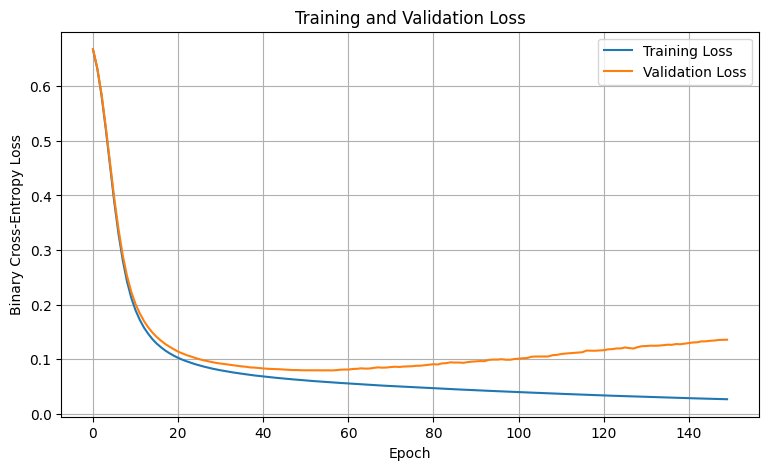

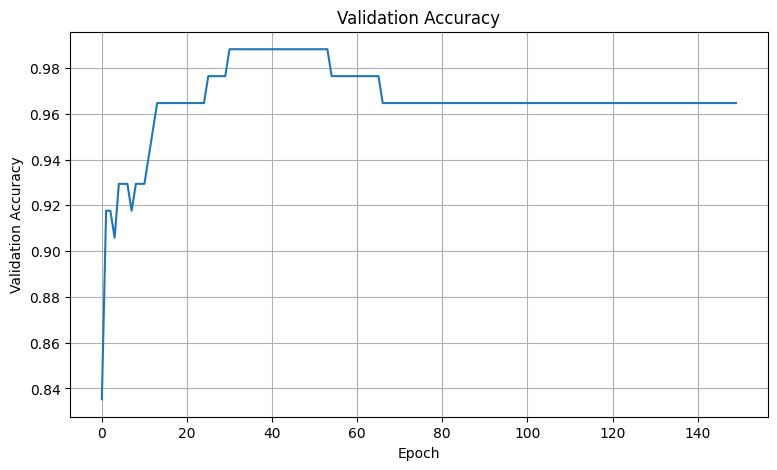

In [19]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.plot(adam_history["train_loss"], label="Training Loss")
plt.plot(adam_history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(adam_history["val_accuracy"])
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy")
plt.grid(True)
plt.show()


In [20]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

test_probabilities, _ = forward_pass(X_test, adam_params)
y_pred = (test_probabilities >= 0.5).astype(int)

print("Test Accuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Benign", "Malignant"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Test Accuracy: 98.84 %

Classification Report:
              precision    recall  f1-score   support

      Benign       0.98      1.00      0.99        54
   Malignant       1.00      0.97      0.98        32

    accuracy                           0.99        86
   macro avg       0.99      0.98      0.99        86
weighted avg       0.99      0.99      0.99        86

Confusion Matrix:
[[54  0]
 [ 1 31]]


In [21]:

import joblib

model_bundle = {
    "params": adam_params,
    "scaler": scaler,
    "feature_names": list(df.drop(columns=["diagnosis"]).columns),
    "threshold": 0.5
}

joblib.dump(model_bundle, "breast_cancer_model.joblib")

print("Model saved successfully!")


Model saved successfully!


In [22]:

import pickle

with open("breast_cancer_model.pkl", "wb") as file:
    pickle.dump(model_bundle, file)

print("Model saved using Pickle successfully!")


Model saved using Pickle successfully!


In [23]:

import joblib

loaded_model = joblib.load("breast_cancer_model.joblib")

print("Model loaded successfully!")
print("Number of input features:",
      len(loaded_model["feature_names"]))
print("Decision threshold:", loaded_model["threshold"])


Model loaded successfully!
Number of input features: 30
Decision threshold: 0.5


In [24]:

# Recover the original values of one test sample
sample_raw = scaler.inverse_transform(X_test[0:1])

# Scale it using the scaler loaded from the saved model
sample_scaled = loaded_model["scaler"].transform(sample_raw)

# Predict using the saved network parameters
probability, _ = forward_pass(
    sample_scaled,
    loaded_model["params"]
)

p = float(probability[0, 0])
prediction = int(p >= loaded_model["threshold"])

print("Predicted class:",
      "Malignant" if prediction == 1 else "Benign")
print("Malignant probability:", round(p, 4))
print("Actual class:",
      "Malignant" if y_test[0, 0] == 1 else "Benign")


Predicted class: Malignant
Malignant probability: 1.0
Actual class: Malignant


In [25]:

def predict_sample(raw_sample, model_path="breast_cancer_model.joblib"):
    bundle = joblib.load(model_path)

    raw_sample = np.asarray(raw_sample, dtype=float).reshape(1, -1)

    if raw_sample.shape[1] != len(bundle["feature_names"]):
        raise ValueError("Expected 30 input features.")

    scaled_sample = bundle["scaler"].transform(raw_sample)

    probability, _ = forward_pass(
        scaled_sample,
        bundle["params"]
    )

    p = float(probability[0, 0])

    return {
        "prediction": "Malignant" if p >= bundle["threshold"] else "Benign",
        "malignant_probability": round(p, 4)
    }


# Test the function with one original, unscaled sample
print(predict_sample(X[0]))


{'prediction': 'Malignant', 'malignant_probability': 1.0}


In [26]:

def predict_sample(raw_sample, model_path="breast_cancer_model.joblib"):
    bundle = joblib.load(model_path)

    raw_sample = np.asarray(raw_sample, dtype=float).reshape(1, -1)

    if raw_sample.shape[1] != len(bundle["feature_names"]):
        raise ValueError("Expected 30 input features.")

    scaled_sample = bundle["scaler"].transform(raw_sample)

    probability, _ = forward_pass(
        scaled_sample,
        bundle["params"]
    )

    p = float(probability[0, 0])

    return {
        "prediction": "Malignant" if p >= bundle["threshold"] else "Benign",
        "malignant_probability": round(p, 4)
    }


# Test the function with one original, unscaled sample
print(predict_sample(X[0]))


{'prediction': 'Malignant', 'malignant_probability': 1.0}


In [27]:

from google.colab import files

files.download("breast_cancer_model.joblib")
files.download("breast_cancer_model.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:

sgd_params, sgd_history = train_model(
    X_train, y_train,
    X_val, y_val,
    optimizer="sgd",
    epochs=150,
    batch_size=32,
    lr=0.01
)


Epoch 25/150 | Train Loss: 0.1981 | Val Loss: 0.1931 | Val Accuracy: 0.9529
Epoch 50/150 | Train Loss: 0.1370 | Val Loss: 0.1307 | Val Accuracy: 0.9529
Epoch 75/150 | Train Loss: 0.1125 | Val Loss: 0.1086 | Val Accuracy: 0.9529
Epoch 100/150 | Train Loss: 0.0989 | Val Loss: 0.0965 | Val Accuracy: 0.9765
Epoch 125/150 | Train Loss: 0.0896 | Val Loss: 0.0893 | Val Accuracy: 0.9765
Epoch 150/150 | Train Loss: 0.0829 | Val Loss: 0.0846 | Val Accuracy: 0.9765


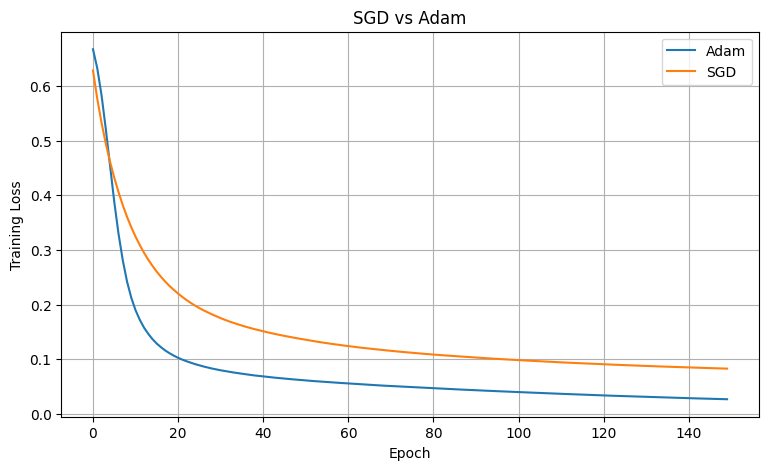

Adam final validation loss: 0.1358
SGD final validation loss: 0.0846
Adam validation accuracy: 96.47 %
SGD validation accuracy: 97.65 %


In [29]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(adam_history["train_loss"], label="Adam")
plt.plot(sgd_history["train_loss"], label="SGD")

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("SGD vs Adam")
plt.legend()
plt.grid(True)
plt.show()

print("Adam final validation loss:",
      round(adam_history["val_loss"][-1], 4))

print("SGD final validation loss:",
      round(sgd_history["val_loss"][-1], 4))

print("Adam validation accuracy:",
      round(adam_history["val_accuracy"][-1] * 100, 2), "%")

print("SGD validation accuracy:",
      round(sgd_history["val_accuracy"][-1] * 100, 2), "%")
